# Behavior analyses on rollouts vs real fish


## Stimulus-programme rollout tool

This section generates simulated fish trajectories from a trained model, given a stimulus trajectory file.  
The generated rollouts are then compared to real fish trajectories in the same stimulus programme. Code to generate rollouts is taken from `stimulus_tool.ipynb`.

**Inputs :**

 - stimulus trajectory file : `assets/stimulus/2025.02.20-0957_trajectory_GsizeMotionSingle_180min.csv.gz` 
 - trained model : `assets/models/ladder_b_indiv.pt` 
 
 Choosing rollout parameters : 

 - MODEL_KEY : J10 is current best model, it is the only one in the current keys available for the repo.
 - N_ROLLOUTS : number of rollouts to generate, 3 as a minimum is recommended to be able to generate the mp4 file correctly (video shows first 3 rollouts)
 - WINDOWS : set `WINDOWS = [(lo, hi, 'label'), (lo2, hi2, 'label2')]` in frames.
 - VIDEO_SPEED : speed of mp4 video render, 3.0 is default.

In [1]:
import sys, time, json, re
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / 'scripts').exists() and (ROOT.parent / 'scripts').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'scripts'))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns
if not hasattr(np, '_core'):                 # load Colab (numpy 2) checkpoints under numpy 1
    import numpy.core as _nc; np._core = _nc

import evaluate as E, fit_MLP_border as MB, fit_MLP_mix as MX
import stim_program as SP, stim_rollout as SR, tool_video as TV, tool_reference as TR
from rollout_bouts import real_bout_dict, rollout_bout_dict, enrich_bout_df


In [2]:
def pick(*candidates):
    """First path that exists, else None. Everything the tool reads is resolved this way:
    the full local dataset when you have it, the small shipped assets/ copy otherwise."""
    for c in candidates:
        p = ROOT / c
        if p.exists():
            return p
    return None

TRAJ_FILE = pick('assets/stimulus/2025.02.20-0957_trajectory_GsizeMotionSingle_180min.csv.gz')
ROI_FILE  = pick('assets/ROIdef2025-02-20T12_09_16.csv')
BOUTS     = None      # None in a clean clone
REFERENCE = pick('assets/real_reference.npz')
DATA_DIR  = pick('data/20250220_MP_01_GsizeMotionSingle')   # full-res real tracking, if present

# Params
MODEL_KEY  = 'J10'
N_ROLLOUTS = 15              # matches the real fish count (15) for comparable SEM/error bars
SEED       = 0
WINDOWS    = None           # None = auto-pick two contrasting blocks
VIDEO_SPEED = 3.0           # 3x real time
OUT_DIR = ROOT / 'tool_videos'
SPEED_THRESH_K = 1.0        # real-data bout-detection threshold (segment_bouts.segment_fish)
PX_TO_MM = 3.67

plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.facecolor': 'white', 'savefig.facecolor': 'white', 'figure.dpi': 110})
REAL, GEN = '#3C3C3C', '#1F3B8C'
print('ROOT     ', ROOT)
print('python   ', sys.version.split()[0], '| numpy', np.__version__)
print('stimulus ', TRAJ_FILE.name if TRAJ_FILE else 'MISSING')
print('roi      ', ROI_FILE.name if ROI_FILE else 'MISSING')
print('reference', 'bouts CSV (full local data)' if BOUTS else
                   (REFERENCE.name if REFERENCE else 'MISSING'))
print('real data', DATA_DIR if DATA_DIR else 'not found -- real-vs-generated comparison will be skipped')
assert TRAJ_FILE and ROI_FILE and (BOUTS or REFERENCE), 'missing inputs -- see the README'


ROOT      /Users/matilde/code/digital_twin
python    3.13.5 | numpy 2.4.3
stimulus  2025.02.20-0957_trajectory_GsizeMotionSingle_180min.csv.gz
roi       ROIdef2025-02-20T12_09_16.csv
reference real_reference.npz
real data /Users/matilde/code/digital_twin/data/20250220_MP_01_GsizeMotionSingle


In [3]:
# key -> candidate paths, first existing wins. Only J10 ships with the repo
MODELS = {
    'J10':           ['assets/models/ladder_b_indiv.pt',        # the thesis J10 (traj AUC 0.704)
                      'notebooks/_zip_full/ladder_b_indiv.pt'],
    'J10_150ep':     ['ladder_b_indiv150.pt'],                  # same recipe, 150 epochs
    'J10_cal2q':     ['ladder_b_indiv150_cal2q.pt'],            # recalibrated containment
    'J10_psi_basis': ['ladder_b_indiv_psib_cal2q.pt'],          # J10 + psi-frame + border basis
    'J17':           ['ladder_re_swap_gr.pt'],                  # fitted per-fish latent, m=2
}
_p = pick(*MODELS[MODEL_KEY])
if _p is None:
    raise FileNotFoundError(
        f"{MODEL_KEY} not found. Tried: {MODELS[MODEL_KEY]}. "
        f"Only 'J10' ships with the repo; the others need the full research checkout.")
model = MX.load_mix(str(_p))
cf = model._cfg_feat

records = MB.build_border_records(E.load_bouts(str(BOUTS)), roi_path=str(ROI_FILE)) if BOUTS else None
ref = TR.reference_from_records(records) if records else TR.load_reference(REFERENCE)


In [4]:
# Load stim program file
program = SP.load_program(TRAJ_FILE)
print(program.summary())

# Show the first 10 rows of the block table
program.block_table().head(10)

2025.02.20-0957_trajectory_GsizeMotionSingle_180min.csv.gz: 315000 frames (175.0 min @ 30 fps), 8 dot slots
  191 blocks -> 95 stimulus / 96 pause
  16 conditions; N in [1, 2, 4, 6, 8]; moving 60 / static 35


,block,label,start_frame,end_frame,dur_s,n_dots,moving,side,is_stim
0,0,none,0,1500,50.0,0.0,False,none,False
1,1,CLsemi1800_g4-0_s3.5-3.5,1500,3300,60.0,4.0,True,left,True
2,2,none,3300,4800,50.0,0.0,False,none,False
3,3,CLsemi1800_g0-2_s3.5-3.5,4800,6600,60.0,2.0,True,right,True
4,4,none,6600,8100,50.0,0.0,False,none,False
5,5,CLsemi1800_g0-4_s3.5-3.5,8100,9900,60.0,4.0,True,right,True
6,6,none,9900,11400,50.0,0.0,False,none,False
7,7,CLsemi1800_g8-0_s3.5-3.5,11400,13200,60.0,8.0,True,left,True
8,8,none,13200,14700,50.0,0.0,False,none,False
9,9,CLsemi1800_g0-4_s0-0,14700,16500,60.0,4.0,False,right,True


In [5]:
# NGenerate rollouts
dish = SR.default_dish(roi_path=str(ROI_FILE))

t0 = time.time()
rollouts = SR.rollout_many(model, program, N_ROLLOUTS, seed=SEED,
                           dish=dish, pose_sampler=ref.sample_start_pose)
print(f'{N_ROLLOUTS} rollouts in {time.time() - t0:.1f}s')


  rollout 0: 4604 bouts, last onset 174.94 of 175.00 min (short by 3.4s), median dt 1.52s, max r/R 0.998, 0.6s


  rollout 1: 5356 bouts, last onset 174.99 of 175.00 min (short by 0.6s), median dt 1.33s, max r/R 0.993, 0.7s


  rollout 2: 5597 bouts, last onset 175.00 of 175.00 min (short by 0.2s), median dt 1.33s, max r/R 0.997, 0.7s


  rollout 3: 4840 bouts, last onset 174.99 of 175.00 min (short by 0.6s), median dt 1.61s, max r/R 0.994, 0.6s


  rollout 4: 4326 bouts, last onset 174.97 of 175.00 min (short by 1.5s), median dt 1.70s, max r/R 0.999, 0.5s


...

  rollout 10: 4688 bouts, last onset 174.97 of 175.00 min (short by 1.8s), median dt 1.56s, max r/R 0.999, 0.6s


  rollout 11: 4846 bouts, last onset 174.98 of 175.00 min (short by 1.2s), median dt 1.54s, max r/R 1.000, 0.6s


  rollout 12: 6526 bouts, last onset 175.00 of 175.00 min (short by 0.1s), median dt 1.09s, max r/R 1.000, 0.8s


  rollout 13: 5611 bouts, last onset 174.80 of 175.00 min (short by 11.8s), median dt 1.29s, max r/R 0.994, 0.7s


  rollout 14: 4181 bouts, last onset 175.00 of 175.00 min (short by 0.2s), median dt 1.79s, max r/R 0.999, 0.5s
15 rollouts in 10.1s


## Bouts-based analyses, real and generated
Analyses of bouts extracted from real fish trajectories and generated rollouts, in bout format (not frame-based). Analyses taken from `semicl_analyses.ipynb`.

In [6]:
# Enrich rollouts with extra info (stimulus, position, distance to dots, etc.)
gen_bouts = {k: enrich_bout_df(df, program) for k, df in rollout_bout_dict(rollouts).items()}
gen_all = pd.concat(gen_bouts.values(), ignore_index=True)
print(f'{len(gen_bouts)} rollouts, {len(gen_all)} bouts total')

# Tranform real frame-based trajectories to match the generated bout format and enrich with extra info
real_bouts = {k: enrich_bout_df(df, program)
                for k, df in real_bout_dict(DATA_DIR, speed_thresh_k=SPEED_THRESH_K).items()}
real_all = pd.concat(real_bouts.values(), ignore_index=True)
print(f'{len(real_bouts)} real fish, {len(real_all)} bouts total')

15 rollouts, 79850 bouts total


15 real fish, 70590 bouts total


In [7]:
# Styling, names and color maps for plots -- STIMULI_ORDER/STIM_35/STIM_0 are derived from the actual bout data below 
MOTION_CMAP, STATIC_CMAP = 'RdPu', 'Oranges'

def parse_stim(stim):
    """'d1s3.5' -> (1, 3.5). (None, None) for non-matching strings."""
    m = re.match(r"d(\d+)s([\d.]+)$", stim)
    return (int(m.group(1)), float(m.group(2))) if m else (None, None)

def is_motion(stim):
    d, s = parse_stim(stim)
    return d is not None and s not in (None, 0.0)

def is_static(stim):
    d, s = parse_stim(stim)
    return d is not None and s == 0.0

def auto_label(stim):
    if stim == 'inter_stim_pause':
        return 'control'
    d, s = parse_stim(stim)
    return f"{d} - {'static' if s == 0 else 'motion'}" if d is not None else stim

def dots_label(stim):
    return 'control' if stim == 'inter_stim_pause' else str(parse_stim(stim)[0])

# Stimulus order and color maps for plots
# It orders the stimuli by (static/motion, dot count, speed) and assigns a color to each dot count
_seen_stimuli = set(real_all['stimulus']).union(gen_all['stimulus']) - {'inter_stim_pause'}
STIMULI_ORDER = sorted(_seen_stimuli, key=lambda s: (is_static(s),) + parse_stim(s))
STIM_35 = [s for s in STIMULI_ORDER if is_motion(s)]   # name kept for compat; = the motion stimuli
STIM_0  = [s for s in STIMULI_ORDER if is_static(s)]   # = the static stimuli

motion_stims, static_stims = STIM_35, STIM_0
motion_dots_sorted = sorted({parse_stim(s)[0] for s in motion_stims})
static_dots_sorted = sorted({parse_stim(s)[0] for s in static_stims})

motion_palette = sns.color_palette(MOTION_CMAP, len(motion_dots_sorted))
static_palette = sns.color_palette(STATIC_CMAP, len(static_dots_sorted))
dot_to_motion_color = dict(zip(motion_dots_sorted, motion_palette))
dot_to_static_color = dict(zip(static_dots_sorted, static_palette))

color_map = {s: dot_to_motion_color[parse_stim(s)[0]] for s in motion_stims}
color_map.update({s: dot_to_static_color[parse_stim(s)[0]] for s in static_stims})
color_map['inter_stim_pause'] = 'gray'


### 1. Occupancy maps

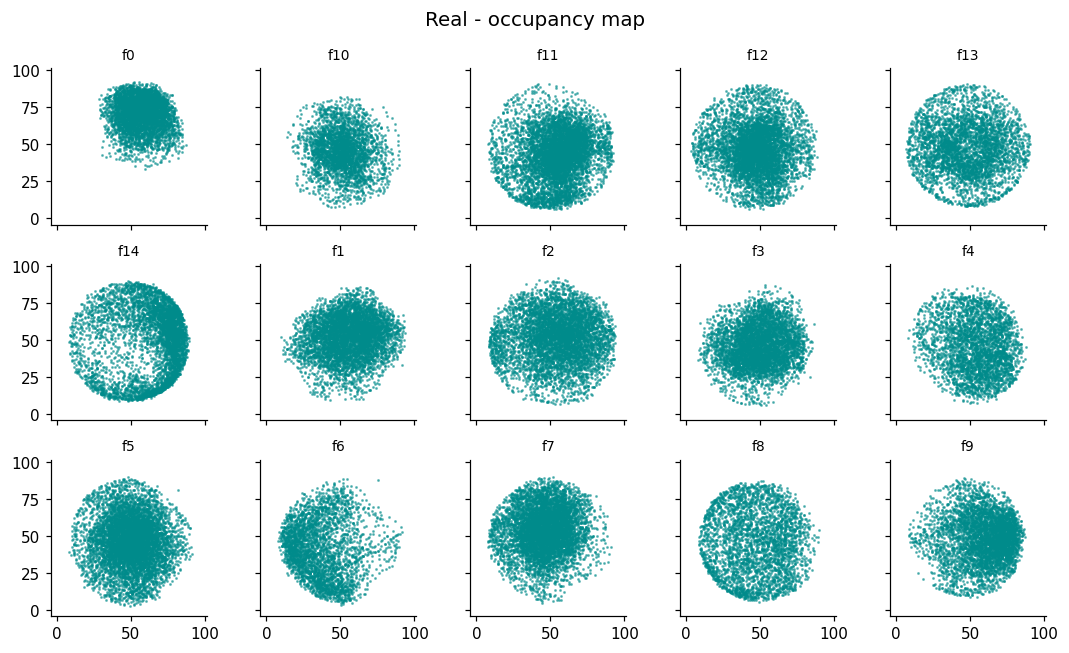

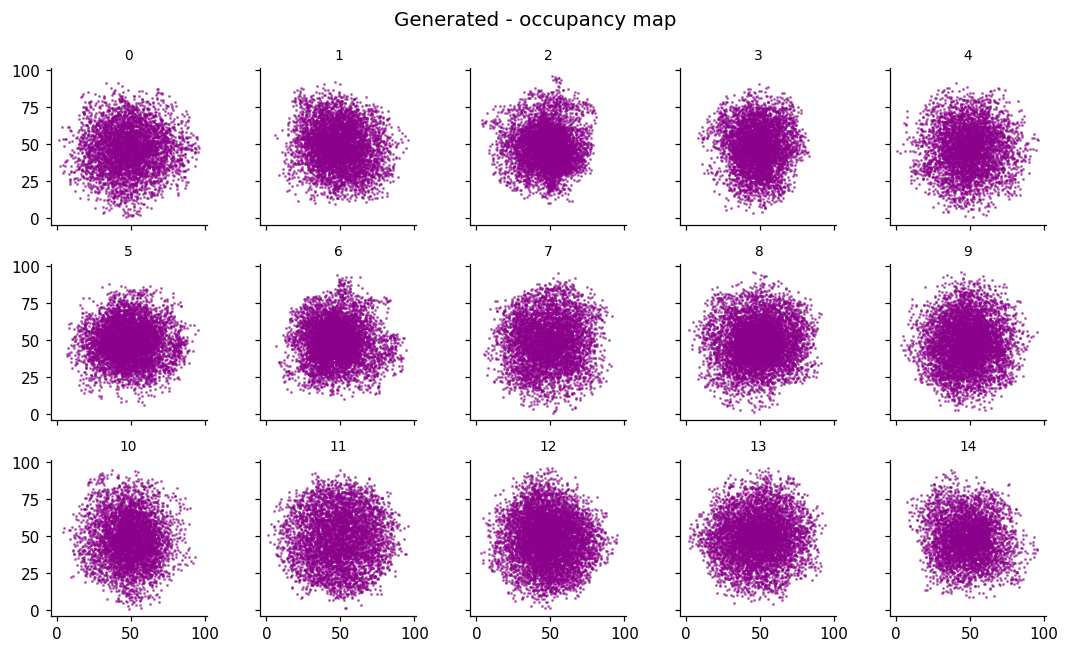

In [8]:
# Transform the bout data to a common scale (mm) and compute the overall x/y limits for the scatter plots
_pad = 5
xlim = (min(real_all['x_px'].min() if not real_all.empty else np.inf, gen_all['x_px'].min()) / PX_TO_MM - _pad,
       max(real_all['x_px'].max() if not real_all.empty else -np.inf, gen_all['x_px'].max()) / PX_TO_MM + _pad)
ylim = (min(real_all['y_px'].min() if not real_all.empty else np.inf, gen_all['y_px'].min()) / PX_TO_MM - _pad,
       max(real_all['y_px'].max() if not real_all.empty else -np.inf, gen_all['y_px'].max()) / PX_TO_MM + _pad)

# set color for real vs generated scatter plots
COLORS = {'Real': 'darkcyan', 'Generated': 'darkmagenta'}

for bouts_dict, title in [(real_bouts, 'Real'), (gen_bouts, 'Generated')]:
    if not bouts_dict:
        print(f'{title}: no data'); continue
    
    ids = list(bouts_dict)
    ncols = 5
    nrows = int(np.ceil(len(ids) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(10, 2 * nrows), sharex=True, sharey=True)
    axes_flat = np.atleast_1d(axes).ravel()
    for ax, fid in zip(axes_flat, ids):
        df = bouts_dict[fid]
        ax.scatter(df['x_px'] / PX_TO_MM, df['y_px'] / PX_TO_MM, s=0.9, alpha=0.5, color=COLORS[title])
        ax.set_title(str(fid), fontsize=9)
        ax.set_xlim(*xlim); ax.set_ylim(*ylim)
        ax.set_aspect('equal')
    for ax in axes_flat[len(ids):]:
        ax.axis('off')
    fig.suptitle(f'{title} - occupancy map', fontsize=13)
    plt.tight_layout()
    plt.show()


### 2. Position after stimulus appearance, by side & condition

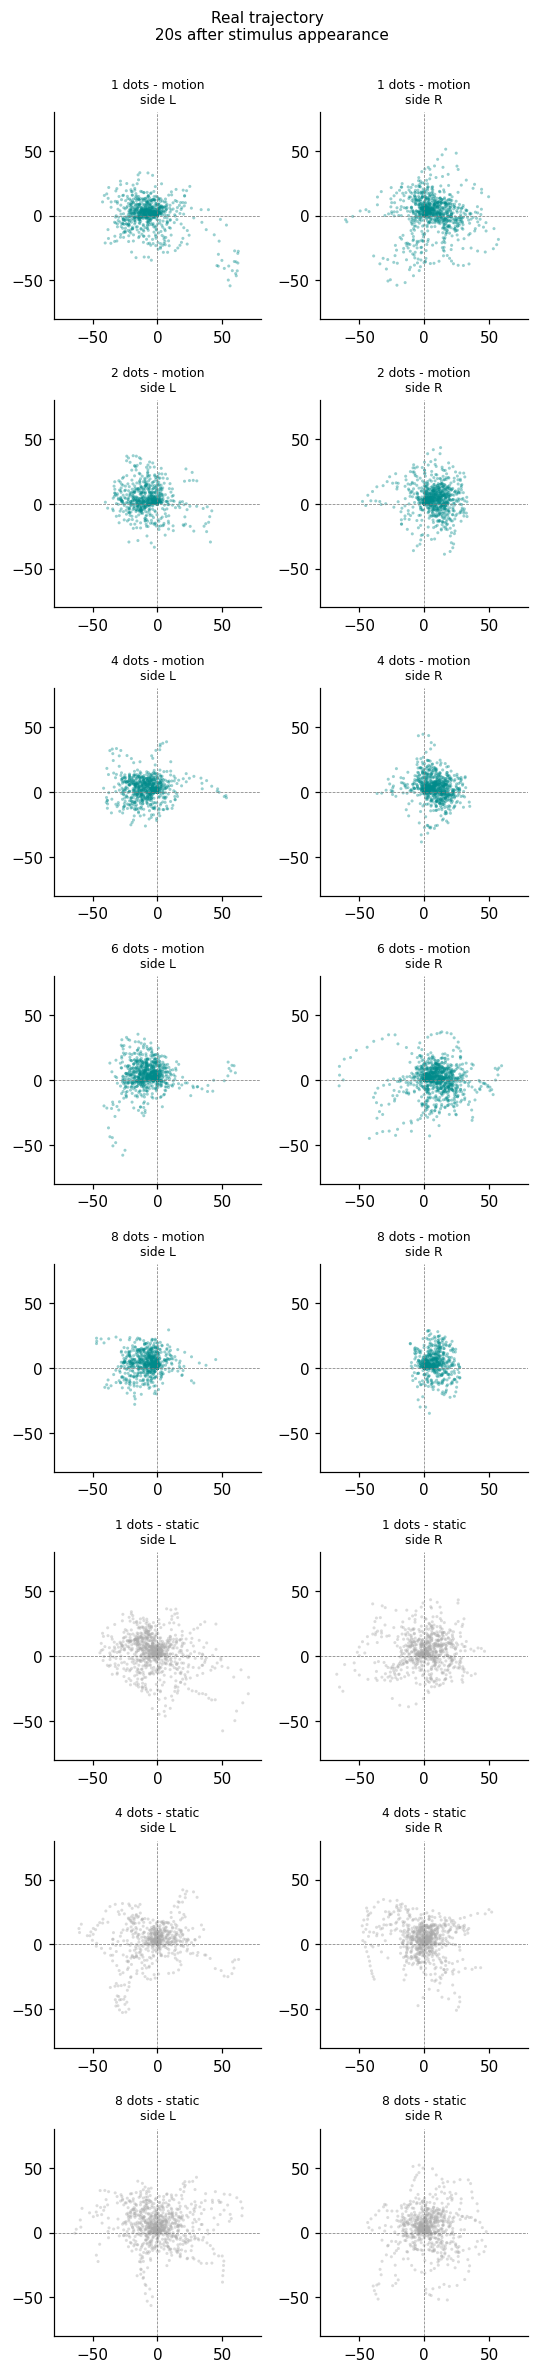

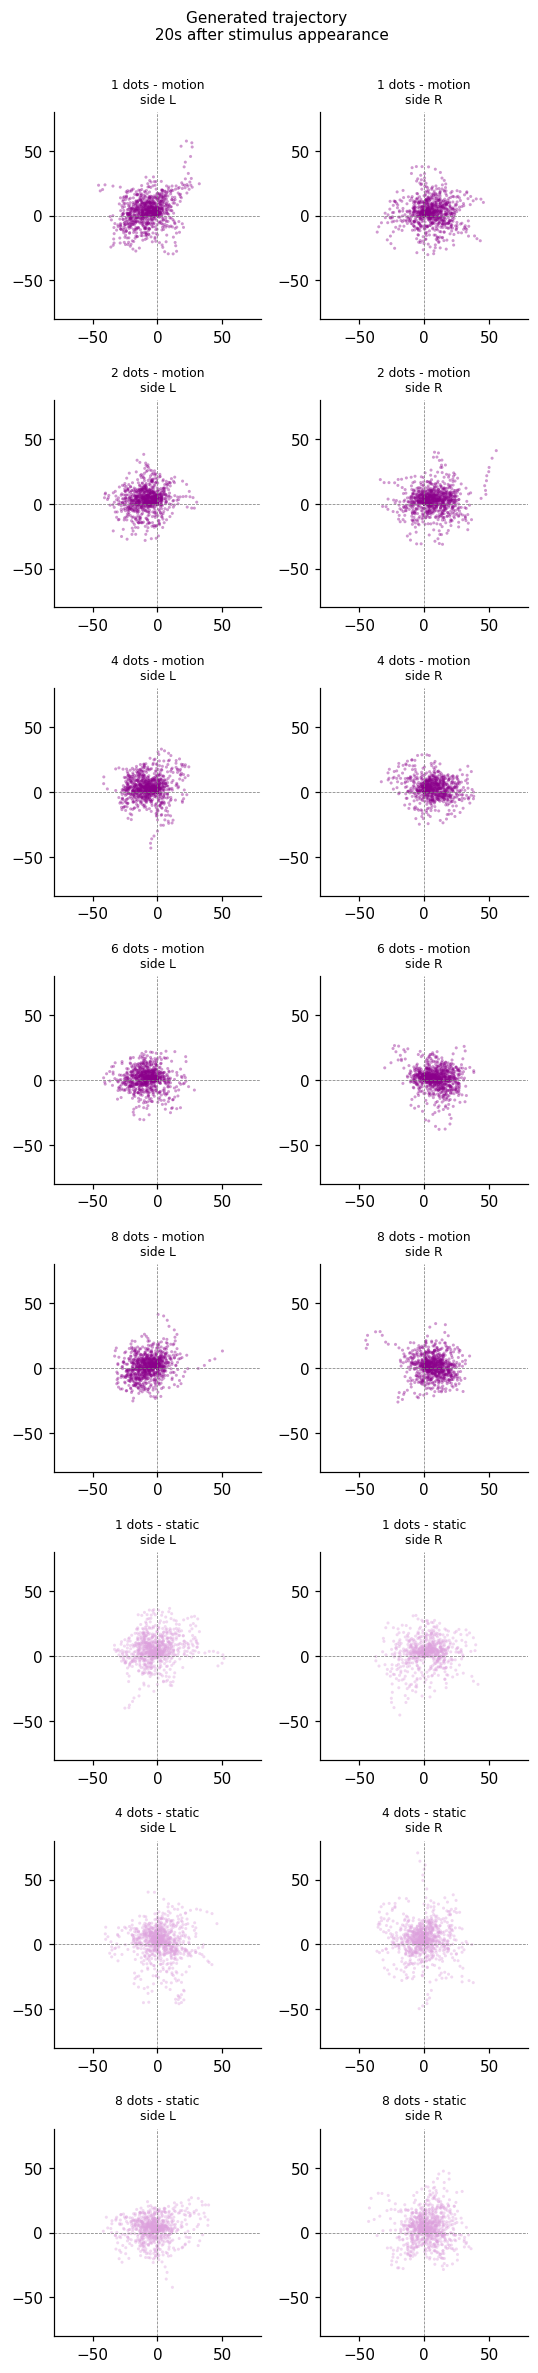

In [9]:
COND_COLORS = {'Real': {'motion': 'darkcyan', 'static': 'darkgrey'},
              'Generated': {'motion': 'darkmagenta', 'static': 'plum'}}

# Scatter plots of the first s of each bout, by stimulus and side
SECONDS_AFTER_ONSET = 20
fig_h = 2.7 * len(STIMULI_ORDER)
title_margin_in = 0.05   # fixed inches reserved for the suptitle, not a fraction of fig_h --
                         # fig_h grows with more stimuli, so a fixed FRACTION (the old 0.97) would
                         # leave an increasingly large empty gap above the plots.

for bouts_dict, title in [(real_bouts, 'Real'), (gen_bouts, 'Generated')]:
    df = pd.concat(bouts_dict.values(), ignore_index=True) if bouts_dict else pd.DataFrame()
    fig, axes = plt.subplots(len(STIMULI_ORDER), 2, figsize=(5, fig_h))
    for row, stim in enumerate(STIMULI_ORDER):
        for col, side in enumerate(['L', 'R']):
            ax = axes[row, col]
            if not df.empty:
                sub = df[(df['stimulus'] == stim) & (df['stim_side'] == side)
                        & (df['t_since_onset_s'] < SECONDS_AFTER_ONSET)]
                color = COND_COLORS[title]['motion' if is_motion(stim) else 'static']
                ax.scatter(sub['x_rot'], sub['y_rot'], s=4, alpha=0.4, color=color, edgecolor='none')
            ax.set_title(f'{dots_label(stim)} dots - {"motion" if is_motion(stim) else "static"}\nside {side}',
                        fontsize=8)
            ax.axhline(0, color='grey', linewidth=0.5, linestyle='--')
            ax.axvline(0, color='grey', linewidth=0.5, linestyle='--')
            ax.set_xlim(-80, 80); ax.set_ylim(-80, 80)
            ax.set_aspect('equal')
    fig.suptitle(f'{title} trajectory \n {SECONDS_AFTER_ONSET}s after stimulus appearance', fontsize=10,
                y=1 - 0.05 / fig_h)
    plt.tight_layout(rect=[0, 0, 1, 1 - title_margin_in / fig_h])
    plt.show()


### 3. Distance fish–dots over time

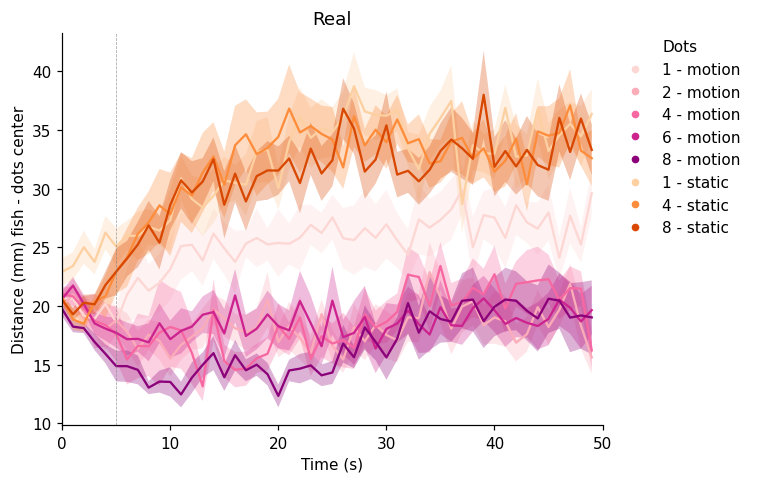

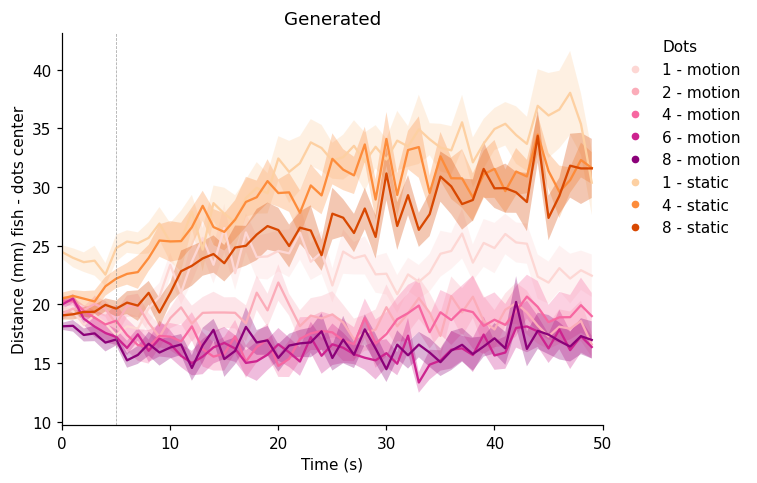

In [10]:
# Bin bout onsets into 1s-wide time bins, average per individual first (so a bouty individual
# doesn't dominate), then mean+-SEM across individuals per bin -- the usual real vs generated
# overlay isn't used here (color already encodes the stimulus), so this is one figure per dataset.

for bouts_dict, title in [(real_bouts, 'Real'), (gen_bouts, 'Generated')]:
    df = pd.concat(bouts_dict.values(), ignore_index=True) if bouts_dict else pd.DataFrame()
    fig, ax = plt.subplots(figsize=(7, 4.5))
    legend_handles = []
    for stim in STIMULI_ORDER:
        color = color_map.get(stim, 'gray')
        legend_handles.append(Line2D([0], [0], marker='o', color=color, linestyle='None',
                                     markersize=4, label=auto_label(stim)))
        if df.empty:
            continue
        sub = df[(df['stimulus'] == stim) & (df['t_since_onset_s'] < 50)].copy()
        if sub.empty:
            continue
        sub['time_bin'] = (sub['t_since_onset_s'] // 1.0) * 1.0
        per_ind = sub.groupby(['fish_id', 'time_bin'])['dist_mm'].mean().reset_index()
        grouped = per_ind.groupby('time_bin')['dist_mm']
        avg, sem = grouped.mean(), grouped.sem()
        ax.plot(avg.index, avg, color=color)
        ax.fill_between(avg.index, avg - sem, avg + sem, alpha=0.3, color=color, edgecolor='none')
    ax.axvline(5, linestyle='--', linewidth=.5, color='grey', alpha=0.7)
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Distance (mm) fish - dots center')
    ax.set_xlim(0, 50)
    ax.set_title(title)
    ax.legend(handles=legend_handles, title='Dots', loc='upper left', bbox_to_anchor=(1.02, 1),
              borderaxespad=0., frameon=False)
    plt.tight_layout()
    plt.show()


### 4. LR Time Ratio

In [11]:
## Function to compute the left-right time ratio per stimulus and side, averaged across blocks and individuals. 
def lr_ratio_table(bouts_dict, stimuli):
    rows = []
    for fid, df in bouts_dict.items():
        for stim in stimuli:
            for side in ['L', 'R']:
                sub = df[(df['stimulus'] == stim) & (df['stim_side'] == side)]
                if sub.empty:
                    continue
                per_block = []
                for _, blk in sub.groupby('block_id'):
                    left = blk.loc[blk['x_rot'] < 0, 'dt_s'].sum()
                    right = blk.loc[blk['x_rot'] > 0, 'dt_s'].sum()
                    if left + right > 0:
                        per_block.append((left - right) / (left + right))
                if per_block:
                    rows.append(dict(fish_id=fid, stimulus=stim, side=side,
                                     lr_ratio=np.mean(per_block)))
    return pd.DataFrame(rows)

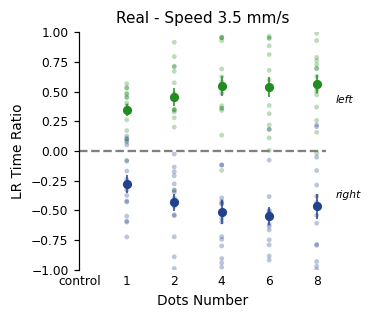

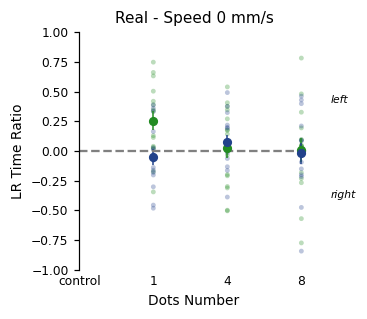

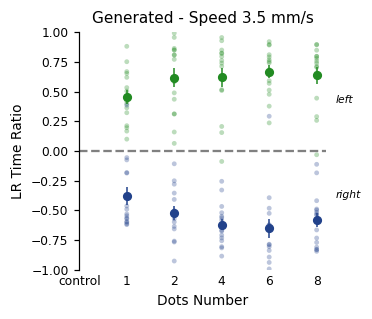

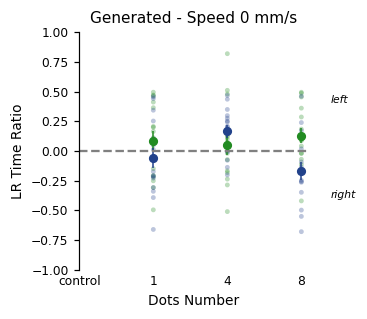

In [57]:
for bouts_dict, dataset_title in [(real_bouts, 'Real'), (gen_bouts, 'Generated')]:
    lr_df = lr_ratio_table(bouts_dict, STIM_35 + STIM_0)
    for stimuli in [STIM_35, STIM_0]:
        if not stimuli:
            continue
        # title reads the actual speed(s) present in this bucket instead of a hardcoded "3.5"/"0"
        speeds = sorted({parse_stim(s)[1] for s in stimuli})
        speed_title = f"Speed {', '.join(f'{s:g}' for s in speeds)} mm/s"
        stimuli_x = ['inter_stim_pause'] + stimuli
        x = np.arange(len(stimuli_x))
        fig, ax = plt.subplots(figsize=(3.5, 3))
        for i, stim in enumerate(stimuli_x):
            for side in ['L', 'R']:
                base_color = '#228B22' if side == 'L' else '#22428B'
                if stim == 'inter_stim_pause':
                    base_color = 'gray' if side == 'L' else 'darkgray'
                sub = (lr_df[(lr_df['stimulus'] == stim) & (lr_df['side'] == side)]
                      if not lr_df.empty else lr_df)
                if sub.empty:
                    continue
                y = sub['lr_ratio'].to_numpy()
                ax.scatter([x[i]] * len(y), y, color=base_color, edgecolor='none', alpha=.3, s=10)
                sem = y.std(ddof=1) / np.sqrt(len(y)) if len(y) > 1 else 0
                ax.errorbar(x[i], y.mean(), yerr=sem, fmt='o', color=base_color, capsize=0,
                            elinewidth=1, markeredgecolor=base_color, markersize=5)
        ax.text(len(stimuli_x) - 0.6, 0.4, 'left', fontsize=7, fontstyle='italic', ha='left')
        ax.text(len(stimuli_x) - 0.6, -0.4, 'right', fontsize=7, fontstyle='italic', ha='left')
        ax.axhline(0, linestyle='--', color='gray')
        ax.set_xticks(x); ax.set_xticklabels([dots_label(s) for s in stimuli_x], ha='center', fontsize=8)
        ax.tick_params(axis='x', length=0)
        ax.tick_params(axis='y', labelsize=8)
        ax.set_ylabel('LR Time Ratio', fontsize=9); ax.set_ylim(-1, 1)
        ax.set_title(f'{dataset_title} - {speed_title}', fontsize=10)
        ax.set_xlabel('Dots Number', fontsize=9)
        ax.spines['bottom'].set_visible(False)
        plt.tight_layout()
        plt.show()
